In [1]:
# pip install pyodbc

df -> 100 Records

80 Training 20 testing

train_df -> 80 records == 100% of training
test_df -> 20 records == 100% of testing

train_df_2 -> 64 records == new 100% of training
val_df -> 16 records == 100% of validation data

In [5]:
import pyodbc
import pandas as pd

In [3]:
pyodbc.drivers()

['SQL Server',
 'SQL Server Native Client 11.0',
 'ODBC Driver 17 for SQL Server']

In [4]:
# YOUR_SERVER\YOUR_INSTANCE

In [5]:
conn = pyodbc.connect(
    'DRIVER={SQL Server};'
    'SERVER=YOUR_SERVER\\YOUR_INSTANCE;'
    'DATABASE=NorDexManufacturing;'
    'Trusted_Connection=yes;'
)

In [6]:
query = 'SELECT * FROM v_ShiftPerformance;'
df = pd.read_sql(query, conn)

NameError: name 'conn' is not defined

In [7]:
df = pd.read_csv('ShiftPerformance.csv')

In [3]:
df.shape

(296334, 31)

In [4]:
df['skill_category'].unique()

array(['Expert', 'Senior', 'Intermediate', 'Junior'], dtype=object)

In [8]:
conn.close()

In [9]:
df.head()

,shift_id,shift_name,start_time,end_time,supervisor_id,production_id,date,units_produced,defect_count,cycle_time_avg,...,issue_type,maintenance_downtime,resolved_by,qc_id,defect_type,severity,inspection_result,temperature,humidity,timestamp
0,1,Morning,06:00:00.0000000,14:00:00.0000000,SUP_01,1,2024-01-01,929,20,35.65,...,NaN,NaN,NaN,1,Material,Minor,Rework,22.3,49.9,2024-01-01 08:00:00
1,1,Morning,06:00:00.0000000,14:00:00.0000000,SUP_01,1,2024-01-01,929,20,35.65,...,NaN,NaN,NaN,2,Assembly,Minor,Accepted,22.3,49.9,2024-01-01 08:00:00
2,1,Morning,06:00:00.0000000,14:00:00.0000000,SUP_01,1,2024-01-01,929,20,35.65,...,NaN,NaN,NaN,3,Dimensional,Minor,Rework,22.3,49.9,2024-01-01 08:00:00
3,1,Morning,06:00:00.0000000,14:00:00.0000000,SUP_01,1,2024-01-01,929,20,35.65,...,NaN,NaN,NaN,4,Dimensional,Minor,Rework,22.3,49.9,2024-01-01 08:00:00
4,1,Morning,06:00:00.0000000,14:00:00.0000000,SUP_01,1,2024-01-01,929,20,35.65,...,NaN,NaN,NaN,5,Cosmetic,Minor,Rework,22.3,49.9,2024-01-01 08:00:00


In [10]:
df.isnull().sum()

shift_id                       0
shift_name                     0
start_time                     0
end_time                       0
supervisor_id                  0
production_id                  0
date                           0
units_produced                 0
defect_count                   0
cycle_time_avg                 0
shift_efficiency_score         0
operator_id                    0
operator_name                  0
experience_level               0
skill_category                 0
machine_id                     0
runtime_hours                  0
downtime_minutes               0
maintenance_flag               0
machine_status                 0
maintenance_id            181103
issue_type                181103
maintenance_downtime      181103
resolved_by               181103
qc_id                          0
defect_type                    0
severity                       0
inspection_result              0
temperature                 1205
humidity                    1205
timestamp 

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296334 entries, 0 to 296333
Data columns (total 31 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   shift_id                296334 non-null  int64  
 1   shift_name              296334 non-null  object 
 2   start_time              296334 non-null  object 
 3   end_time                296334 non-null  object 
 4   supervisor_id           296334 non-null  object 
 5   production_id           296334 non-null  int64  
 6   date                    296334 non-null  object 
 7   units_produced          296334 non-null  int64  
 8   defect_count            296334 non-null  int64  
 9   cycle_time_avg          296334 non-null  float64
 10  shift_efficiency_score  296334 non-null  float64
 11  operator_id             296334 non-null  object 
 12  operator_name           296334 non-null  object 
 13  experience_level        296334 non-null  int64  
 14  skill_category      

In [12]:
df['date'] = pd.to_datetime(df['date'])

In [13]:
shift_kpis = df.groupby('shift_name').agg(
    avg_units=('units_produced', 'mean'),
    total_units=('units_produced', 'sum'),
    avg_cycle_time=('cycle_time_avg', 'mean'),
    avg_defects=('defect_count', 'mean'),
    defect_rate=('defect_count', lambda x:x.sum() / df.loc[x.index, 'units_produced'].sum()),
    avg_downtime=('downtime_minutes', 'mean'),
    total_downtime=('downtime_minutes', 'sum'),
    avg_efficiency=('shift_efficiency_score', 'mean'),
)
shift_kpis

,avg_units,total_units,avg_cycle_time,avg_defects,defect_rate,avg_downtime,total_downtime,avg_efficiency
shift_name,,,,,,,,
Evening,601.050543,61599266,36.025551,21.329079,0.035486,50.569570,5182672.96,76.737957
Morning,846.926073,76046339,35.999287,18.749151,0.022138,29.086002,2611661.18,90.869944
Night,484.765119,50443204,36.028043,21.670998,0.044704,67.857893,7061088.73,61.164965


In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

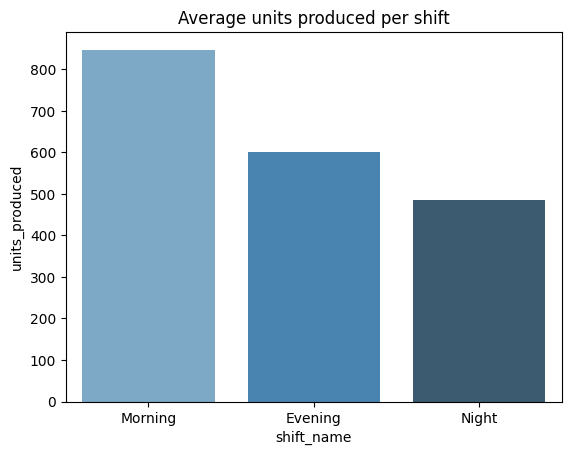

In [15]:
sns.barplot(x='shift_name', y='units_produced', data=df, estimator='mean', palette='Blues_d')
plt.title('Average units produced per shift')
plt.show()

In [16]:
df.columns

Index(['shift_id', 'shift_name', 'start_time', 'end_time', 'supervisor_id',
       'production_id', 'date', 'units_produced', 'defect_count',
       'cycle_time_avg', 'shift_efficiency_score', 'operator_id',
       'operator_name', 'experience_level', 'skill_category', 'machine_id',
       'runtime_hours', 'downtime_minutes', 'maintenance_flag',
       'machine_status', 'maintenance_id', 'issue_type',
       'maintenance_downtime', 'resolved_by', 'qc_id', 'defect_type',
       'severity', 'inspection_result', 'temperature', 'humidity',
       'timestamp'],
      dtype='object')

In [17]:
focus = df[['units_produced', 'defect_count', 'experience_level',
            'downtime_minutes', 'runtime_hours', 'shift_efficiency_score']].corr()

y = mx + b


x = 1 & y = -3
x = 2 & y = -6
x = 3 & y = -9
x = 5 & y = -15

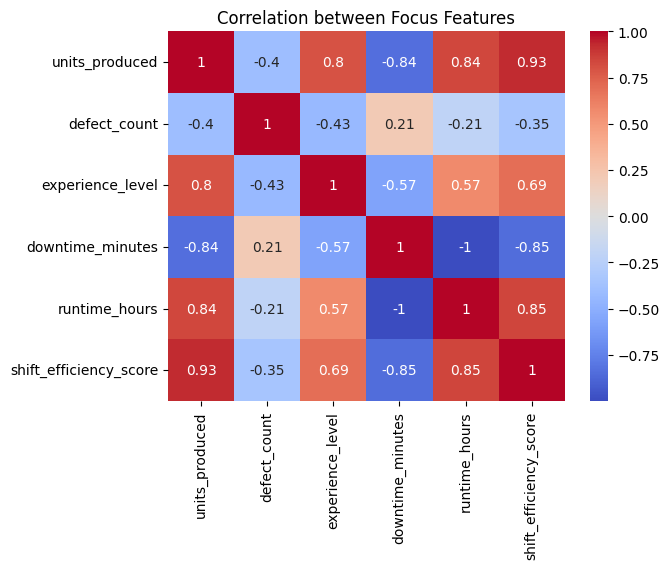

In [18]:
sns.heatmap(focus, annot=True, cmap='coolwarm')
plt.title('Correlation between Focus Features')
plt.show()

 y = mx + b -> linear regression

 x = 1 & y = 3
 x = 2 & y = 6
 x = 5 & y = 15

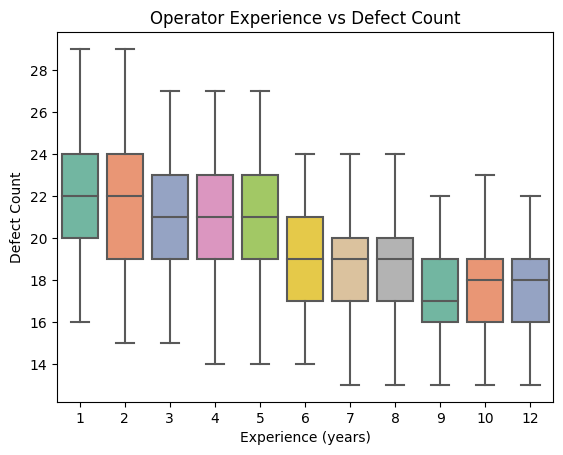

In [19]:
sns.boxplot(data=df, x='experience_level', y='defect_count', palette='Set2')
plt.title('Operator Experience vs Defect Count')
plt.xlabel('Experience (years)')
plt.ylabel('Defect Count')
plt.show()

# Modelling

In [44]:
df.columns

Index(['shift_id', 'shift_name', 'start_time', 'end_time', 'supervisor_id',
       'production_id', 'date', 'units_produced', 'defect_count',
       'cycle_time_avg', 'shift_efficiency_score', 'operator_id',
       'operator_name', 'experience_level', 'skill_category', 'machine_id',
       'runtime_hours', 'downtime_minutes', 'maintenance_flag',
       'machine_status', 'maintenance_id', 'issue_type',
       'maintenance_downtime', 'resolved_by', 'qc_id', 'defect_type',
       'severity', 'inspection_result', 'temperature', 'humidity',
       'timestamp'],
      dtype='object')

In [8]:
feat_X_target = df[['shift_name', 'units_produced', 'defect_count',
       'cycle_time_avg', 'shift_efficiency_score', 'experience_level', 'skill_category', 
       'runtime_hours', 'downtime_minutes', 'maintenance_flag','temperature', 'humidity']]

In [9]:
feat_X_target.isnull().sum()

shift_name                   0
units_produced               0
defect_count                 0
cycle_time_avg               0
shift_efficiency_score       0
experience_level             0
skill_category               0
runtime_hours                0
downtime_minutes             0
maintenance_flag             0
temperature               1205
humidity                  1205
dtype: int64

In [10]:
feat_X_target.dropna(inplace=True)
X = feat_X_target.drop('shift_efficiency_score', axis=1)
y = feat_X_target['shift_efficiency_score']

C:\Users\user\AppData\Local\Temp\ipykernel_24988\639207341.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feat_X_target.dropna(inplace=True)


In [11]:
X.head()

,shift_name,units_produced,defect_count,cycle_time_avg,experience_level,skill_category,runtime_hours,downtime_minutes,maintenance_flag,temperature,humidity
0,Morning,929,20,35.65,7,Expert,7.24,15.39,0,22.3,49.9
1,Morning,929,20,35.65,7,Expert,7.24,15.39,0,22.3,49.9
2,Morning,929,20,35.65,7,Expert,7.24,15.39,0,22.3,49.9
3,Morning,929,20,35.65,7,Expert,7.24,15.39,0,22.3,49.9
4,Morning,929,20,35.65,7,Expert,7.24,15.39,0,22.3,49.9


In [12]:
X.dtypes

shift_name           object
units_produced        int64
defect_count          int64
cycle_time_avg      float64
experience_level      int64
skill_category       object
runtime_hours       float64
downtime_minutes    float64
maintenance_flag      int64
temperature         float64
humidity            float64
dtype: object

In [13]:
y

0         95.945255
1         95.945255
2         95.945255
3         95.945255
4         95.945255
            ...    
296329    65.162771
296330    65.162771
296331    65.162771
296332    65.162771
296333    65.162771
Name: shift_efficiency_score, Length: 295129, dtype: float64

In [14]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [15]:
cat_features = ['shift_name', 'skill_category']
num_features = ['units_produced', 'defect_count',
       'cycle_time_avg', 'experience_level', 'runtime_hours', 
                'downtime_minutes', 'maintenance_flag','temperature', 'humidity']

In [16]:
preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

In [55]:
models = {
    'LinearRegression': LinearRegression(),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=100, random_state=30)
}

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
X_train_2, X_Val, y_train_2, y_Val = train_test_split(X_train, y_train, test_size=0.2, random_state=42) 

In [ ]:
X_train.shape, X_test.shape, X_train_2.shape, X_Val.shape

((236103, 11), (59026, 11), (188882, 11), (47221, 11))

In [58]:
from sklearn.pipeline import Pipeline

In [ ]:
def engineer_features():
    pass

In [59]:
results = {}
fitted_pipelines = {}

for name, est in models.items():
    pipe = Pipeline(steps=[('prep', preprocess), ('model', est)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    results[name] = {
        'R2': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred)
    }
    fitted_pipelines[name] = pipe

In [60]:
results

{'LinearRegression': {'R2': 0.932451197983752, 'MAE': 2.6800106000474004},
 'GradientBoosting': {'R2': 0.9450552496635264, 'MAE': 2.4140259538833195}}

In [61]:
fitted_pipelines

{'LinearRegression': Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('cat',
                                                   OneHotEncoder(handle_unknown='ignore'),
                                                   ['shift_name',
                                                    'skill_category']),
                                                  ('num', 'passthrough',
                                                   ['units_produced',
                                                    'defect_count',
                                                    'cycle_time_avg',
                                                    'experience_level',
                                                    'runtime_hours',
                                                    'downtime_minutes',
                                                    'maintenance_flag',
                                                    'temperature',
                                  

In [62]:
pd.DataFrame(results).T

,R2,MAE
LinearRegression,0.932451,2.680011
GradientBoosting,0.945055,2.414026


In [63]:
import joblib

best_pipe = fitted_pipelines['GradientBoosting']
joblib.dump(best_pipe, 'best_model.pkl')

['best_model.pkl']

Cross validation score

df -> 100 records

k=5

s1 -> 20, s2 -> 20, s3 -> 20, s4 -> 20, s5 -> 20

k-1

s1 === model trained on s5 and evaluated on s1 = 89.0
s2 === model trained on s1 and evaluated on s2 = 90.3
s3 === model trained on s2 and evaluated on s3 = 91.7
s4 === model trained on s3 and evaluated on s4 = 87.6
s5 === model trained on s4 and evaluated on s5 = 89.8
